# Complete Financial Fraud Detection Analysis
## Classical ML + Deep Learning + Graph Neural Networks

**Dataset**: Sparkov credit-card transactions  

**Goal**: Detect rare fraudulent transactions (`is_fraud = 1`) using four complementary modelling families and compare them fairly with rare-event metrics.

| Model family | Technique | Why it is useful for fraud |
|--------------|-----------|----------------------------|
| Classical   | Logistic Regression, Random Forest, **XGBoost** | Strong tabular baselines, fast, interpretable feature importance |
| Deep Learning | PyTorch **Embedding MLP** | Learns dense representations of high-cardinality categoricals (merchant, city, job …) |
| Graph Neural Network | Bipartite **GraphSAGE** (card ↔ merchant) | Captures fraud rings / shared-merchant patterns that pure tabular models miss |
| Hybrid idea | GNN node embeddings → XGBoost | Combines relational structure with powerful tree boosting |



## 0. Environment & Imports

In [1]:
# Core
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import json
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Classical ML
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve,
    classification_report, confusion_matrix,
    PrecisionRecallDisplay, RocCurveDisplay
)
from sklearn.utils.class_weight import compute_class_weight

import xgboost as xgb

# Deep Learning / GNN
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

print(f"PyTorch {torch.__version__} | device = {'cuda' if torch.cuda.is_available() else 'cpu'}")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PyTorch 2.13.0+cpu | device = cpu


## 1. Load the Sparkov Dataset
If you have the full Kaggle dataset (`fraudTrain.csv` / `fraudTest.csv` from kartik2112), simply change the path below.

In [5]:
from pathlib import Path
import pandas as pd

# ============================================================
# Sparkov Fraud Dataset
# ============================================================

DATA_DIR = Path.home() / "Downloads" / "Sparkov data"

# Sparkov training dataset
DATA_PATH = DATA_DIR / "fraudTrain.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Sparkov dataset not found at:\n{DATA_PATH}\n\n"
        "Please check that fraudTrain.csv exists inside:\n"
        f"{DATA_DIR}"
    )

# Load dataset
df = pd.read_csv(DATA_PATH)

print(f"Using dataset: {DATA_PATH}")
print(f"Shape: {df.shape}")

if "is_fraud" in df.columns:
    print(f"Fraud rate: {df['is_fraud'].mean():.3%}")
else:
    print("'is_fraud' column not found.")
    print("Available columns:")
    print(df.columns.tolist())

df.head()

Using dataset: C:\Users\JOY\Downloads\Sparkov data\fraudTrain.csv
Shape: (1296675, 23)
Fraud rate: 0.579%


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [6]:
print("Column types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum().sum())

Column types:
Unnamed: 0                 int64
trans_date_trans_time        str
cc_num                     int64
merchant                     str
category                     str
amt                      float64
first                        str
last                         str
gender                       str
street                       str
city                         str
state                        str
zip                        int64
lat                      float64
long                     float64
city_pop                   int64
job                          str
dob                          str
trans_num                    str
unix_time                  int64
merch_lat                float64
merch_long               float64
is_fraud                   int64
dtype: object

Missing values:
0


## 2. Exploratory Data Analysis (EDA)

Understanding the class imbalance and the strongest signals is essential before modelling.

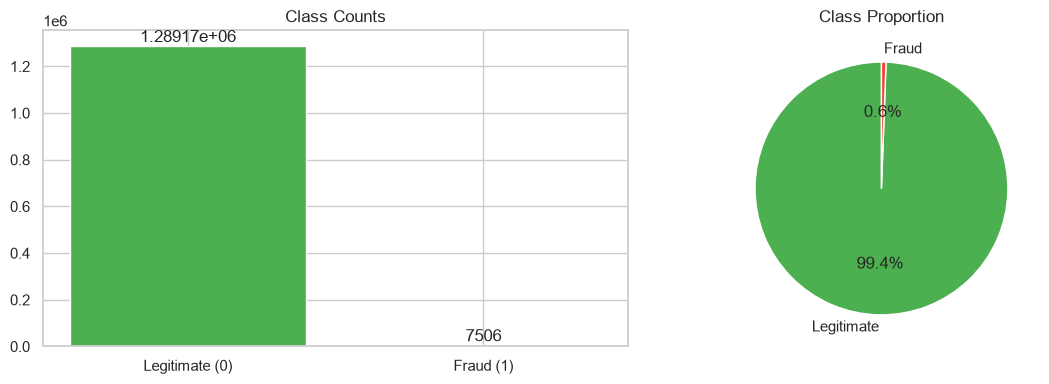

is_fraud
0    1289169
1       7506
Name: count, dtype: int64


In [7]:
# Class balance
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
counts = df["is_fraud"].value_counts()
ax[0].bar(["Legitimate (0)", "Fraud (1)"], counts.values, color=["#4caf50", "#f44336"])
ax[0].set_title("Class Counts")
ax[0].bar_label(ax[0].containers[0])

ax[1].pie(counts, labels=["Legitimate", "Fraud"], autopct="%1.1f%%",
          colors=["#4caf50", "#f44336"], startangle=90)
ax[1].set_title("Class Proportion")
plt.tight_layout()
plt.show()

print(counts)

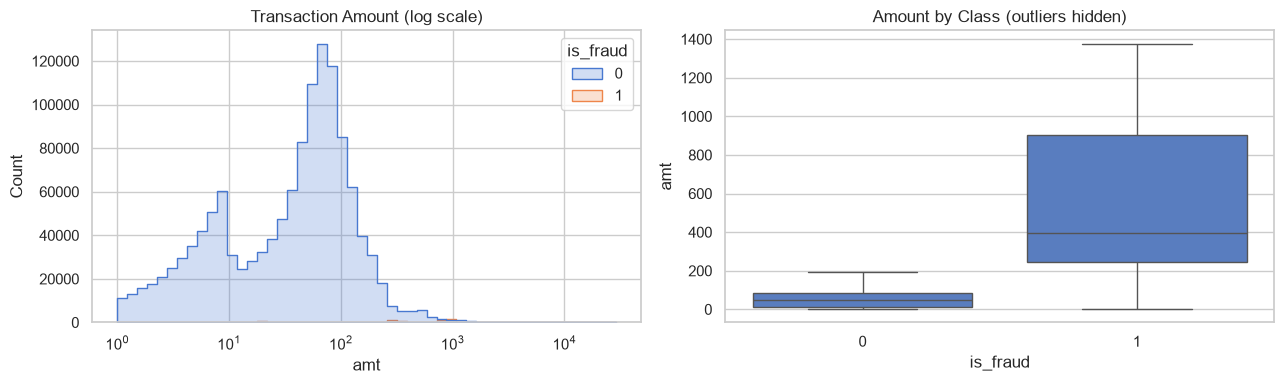

In [8]:
# Amount distribution by class (log scale is useful because fraud often has higher amounts)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="amt", hue="is_fraud", bins=50, log_scale=True, ax=ax[0], element="step")
ax[0].set_title("Transaction Amount (log scale)")

sns.boxplot(data=df, x="is_fraud", y="amt", ax=ax[1], showfliers=False)
ax[1].set_title("Amount by Class (outliers hidden)")
plt.tight_layout()
plt.show()

,fraud_rate,n_tx
category,,
shopping_net,0.017561,97543
misc_net,0.014458,63287
grocery_pos,0.014098,123638
shopping_pos,0.007225,116672
gas_transport,0.004694,131659
misc_pos,0.003139,79655
grocery_net,0.002948,45452
travel,0.002864,40507
entertainment,0.002478,94014


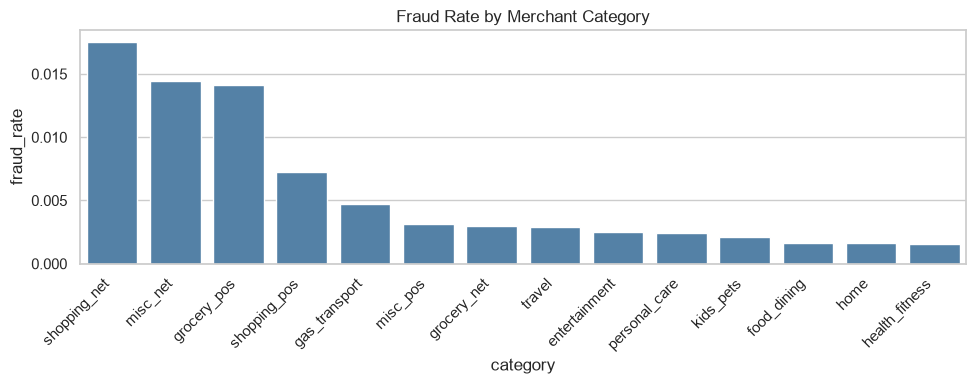

In [9]:
# Category-level fraud rate (classic Sparkov signal)
cat_fraud = (
    df.groupby("category")["is_fraud"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "fraud_rate", "count": "n_tx"})
    .sort_values("fraud_rate", ascending=False)
)
display(cat_fraud.head(10))

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=cat_fraud.reset_index(), x="category", y="fraud_rate", ax=ax, color="steelblue")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_title("Fraud Rate by Merchant Category")
plt.tight_layout()
plt.show()

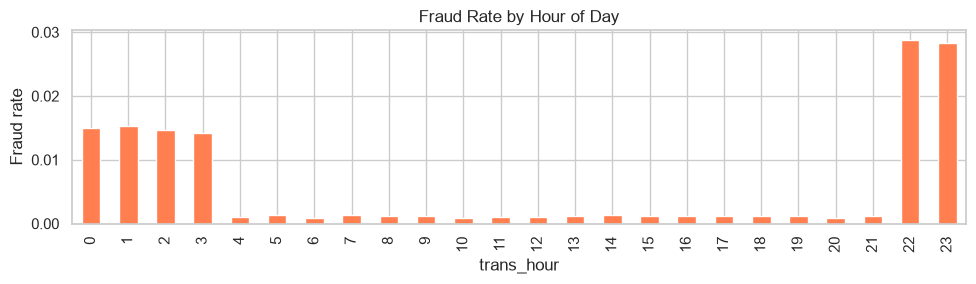

In [11]:
# Time-of-day pattern (fraud often concentrates in unusual hours)
df["trans_hour"] = pd.to_datetime(df["trans_date_trans_time"]).dt.hour
hour_fraud = df.groupby("trans_hour")["is_fraud"].mean()
fig, ax = plt.subplots(figsize=(10, 3))
hour_fraud.plot(kind="bar", ax=ax, color="coral")
ax.set_title("Fraud Rate by Hour of Day")
ax.set_ylabel("Fraud rate")
plt.tight_layout()
plt.show()

## 3. Feature Definition & Leakage-Safe Split

**Critical practice**: fit *all* encoders / scalers **only on the training set**.  
Validation is used solely for threshold selection; the test set is reserved for final reporting.

In [14]:
NUMERICAL = ["distance", "age", "amt", "city_pop"]
CATEGORICAL = [
    "gender", "job", "category", "city", "state", "zip",
    "merchant", "trans_hour", "trans_minute", "trans_second",
    "trans_year", "trans_month", "trans_day"
]
TARGET = "is_fraud"
CARD_COL = "card"
MERCHANT_COL = "merchant"

# Derive time features from the transaction timestamp.
transaction_time = pd.to_datetime(df["trans_date_trans_time"])
df["trans_hour"] = transaction_time.dt.hour
df["trans_minute"] = transaction_time.dt.minute
df["trans_second"] = transaction_time.dt.second
df["trans_year"] = transaction_time.dt.year
df["trans_month"] = transaction_time.dt.month
df["trans_day"] = transaction_time.dt.day

# Convert all categoricals to string for consistent encoding
for c in CATEGORICAL + [CARD_COL, MERCHANT_COL]:
    # Fix dataset naming mismatch: Sparkov uses "cc_num" instead of "card"
    if "card" not in df.columns and "cc_num" in df.columns:
        df = df.rename(columns={"cc_num": "card"})

    # Some datasets may also use a different merchant column name
    if "merchant" not in df.columns and "merchant_name" in df.columns:
        df = df.rename(columns={"merchant_name": "merchant"})

    # Convert all categorical / ID columns to string for consistent encoding
    for c in CATEGORICAL + [CARD_COL, MERCHANT_COL]:
        if c in df.columns:
            df[c] = df[c].astype(str)

# 60 % train / 20 % validation / 20 % test  (stratified)
train_df, temp_df = train_test_split(
    df, test_size=0.40, stratify=df[TARGET], random_state=RANDOM_STATE
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df[TARGET], random_state=RANDOM_STATE
)

print(f"Train : {len(train_df):5d}  fraud rate {train_df[TARGET].mean():.3%}")
print(f"Val   : {len(val_df):5d}  fraud rate {val_df[TARGET].mean():.3%}")
print(f"Test  : {len(test_df):5d}  fraud rate {test_df[TARGET].mean():.3%}")

Train : 778005  fraud rate 0.579%
Val   : 259335  fraud rate 0.579%
Test  : 259335  fraud rate 0.579%


## 4. Preprocessing Helpers

We build two parallel representations:

1. **Tabular** – Label-encoded categoricals + scaled numericals (for classical models & MLP)
2. **Graph** – Card and merchant nodes + edge features (for GraphSAGE)

In [16]:
class TabularPreprocessor:
    """Fit on train only → transform any split."""

    def __init__(self):
        self.label_encoders = {}
        self.scaler = StandardScaler()
        self.cat_cols = CATEGORICAL
        self.num_cols = NUMERICAL

    def fit(self, frame: pd.DataFrame):
        for col in self.cat_cols:
            le = LabelEncoder()
            # reserve 0 for unknown values that appear only in val/test
            le.fit(list(frame[col].unique()) + ["__UNK__"])
            self.label_encoders[col] = le
        self.scaler.fit(frame[self.num_cols])
        return self

    def transform(self, frame: pd.DataFrame):
        cats = np.zeros((len(frame), len(self.cat_cols)), dtype=np.int64)
        for i, col in enumerate(self.cat_cols):
            le = self.label_encoders[col]
            # map unseen categories to __UNK__
            values = frame[col].map(lambda x: x if x in le.classes_ else "__UNK__")
            cats[:, i] = le.transform(values)
        nums = self.scaler.transform(frame[self.num_cols]).astype(np.float32)
        return cats, nums

    def transform_matrix(self, frame: pd.DataFrame) -> np.ndarray:
        """Flat feature matrix for sklearn / XGBoost."""
        cats, nums = self.transform(frame)
        return np.hstack([nums, cats.astype(np.float32)])


def add_derived_features(frame):
    trans_time = pd.to_datetime(frame["trans_date_trans_time"])
    dob = pd.to_datetime(frame["dob"])

    # Age at the time of the transaction.
    frame.loc[:, "age"] = (
        trans_time.dt.year - dob.dt.year
        - (
            (trans_time.dt.month < dob.dt.month)
            | (
                (trans_time.dt.month == dob.dt.month)
                & (trans_time.dt.day < dob.dt.day)
            )
        ).astype(int)
    )

    # Haversine distance, in miles, between cardholder and merchant locations.
    lat1 = np.radians(frame["lat"].astype(float))
    lon1 = np.radians(frame["long"].astype(float))
    lat2 = np.radians(frame["merch_lat"].astype(float))
    lon2 = np.radians(frame["merch_long"].astype(float))
    a = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    )
    frame.loc[:, "distance"] = 2 * 3958.8 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    return frame


train_df = add_derived_features(train_df)
val_df = add_derived_features(val_df)
test_df = add_derived_features(test_df)

prep = TabularPreprocessor().fit(train_df)

X_train = prep.transform_matrix(train_df)
X_val   = prep.transform_matrix(val_df)
X_test  = prep.transform_matrix(test_df)

y_train = train_df[TARGET].values
y_val   = val_df[TARGET].values
y_test  = test_df[TARGET].values

print("Feature matrix shapes:", X_train.shape, X_val.shape, X_test.shape)

Feature matrix shapes: (778005, 17) (259335, 17) (259335, 17)


## 5. Evaluation Utilities (Rare-Event Friendly)

Accuracy is almost meaningless when 97 % of rows are legitimate.  
We focus on:

- **ROC-AUC** – ranking quality
- **PR-AUC** (Average Precision) – the most informative metric for imbalance
- **Precision / Recall / F1** at a validation-chosen threshold

In [17]:
def select_threshold(y_true, y_prob, beta=1.0):
    """Choose threshold that maximises F-beta on the validation set."""
    precision, recall, thresholds = precision_recall_curve(y_true, y_prob)
    # precision_recall_curve returns one extra precision/recall point
    fbeta = (1 + beta**2) * (precision * recall) / (beta**2 * precision + recall + 1e-12)
    best_idx = np.nanargmax(fbeta)
    # thresholds has length len(precision)-1
    thr = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
    return float(thr)


def evaluate(y_true, y_prob, threshold=None, name="model"):
    if threshold is None:
        threshold = 0.5
    y_pred = (y_prob >= threshold).astype(int)

    from sklearn.metrics import precision_score, recall_score, f1_score
    metrics = {
        "roc_auc":   roc_auc_score(y_true, y_prob),
        "pr_auc":    average_precision_score(y_true, y_prob),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall":    recall_score(y_true, y_pred, zero_division=0),
        "f1":        f1_score(y_true, y_pred, zero_division=0),
        "threshold": threshold,
    }
    print(f"\n=== {name} ===")
    for k, v in metrics.items():
        print(f"  {k:12s}: {v:.4f}")
    print(classification_report(y_true, y_pred, target_names=["legit", "fraud"], digits=3))
    return metrics


def plot_curves(y_true, y_prob, name="model"):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    RocCurveDisplay.from_predictions(y_true, y_prob, ax=ax[0], name=name)
    ax[0].set_title("ROC Curve")
    PrecisionRecallDisplay.from_predictions(y_true, y_prob, ax=ax[1], name=name)
    ax[1].set_title("Precision-Recall Curve")
    plt.tight_layout()
    plt.show()


## 6. Classical Models

### 6.1 Logistic Regression (linear baseline)
Simple, fast, and gives a lower bound on performance.

Class weights: {0: np.float64(0.5029114377356978), 1: np.float64(86.36822824156306)}

=== Logistic Regression ===
  roc_auc     : 0.8622
  pr_auc      : 0.2059
  precision   : 0.3803
  recall      : 0.4750
  f1          : 0.4224
  threshold   : 0.9639
              precision    recall  f1-score   support

       legit      0.997     0.995     0.996    257834
       fraud      0.380     0.475     0.422      1501

    accuracy                          0.992    259335
   macro avg      0.689     0.735     0.709    259335
weighted avg      0.993     0.992     0.993    259335



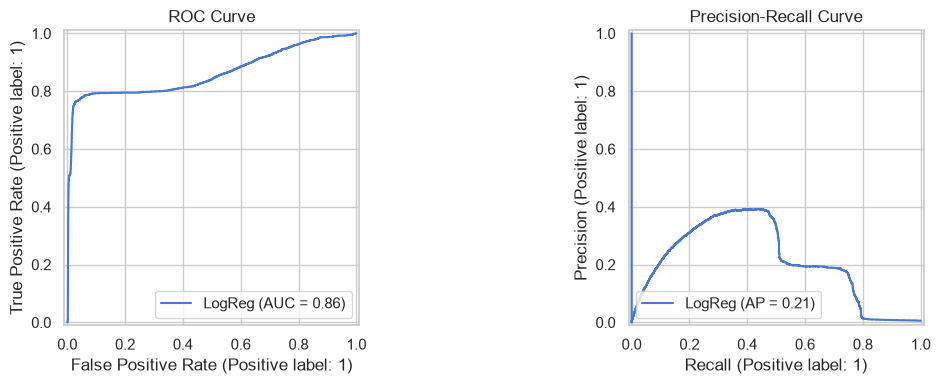

In [18]:
# Class weight to fight imbalance
cw = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}
print("Class weights:", class_weight)

lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
lr.fit(X_train, y_train)

prob_val_lr  = lr.predict_proba(X_val)[:, 1]
prob_test_lr = lr.predict_proba(X_test)[:, 1]

thr_lr = select_threshold(y_val, prob_val_lr)
metrics_lr = evaluate(y_test, prob_test_lr, threshold=thr_lr, name="Logistic Regression")
plot_curves(y_test, prob_test_lr, name="LogReg")

### 6.2 Random Forest


=== Random Forest ===
  roc_auc     : 0.9939
  pr_auc      : 0.8326
  precision   : 0.8396
  recall      : 0.7182
  f1          : 0.7741
  threshold   : 0.7837
              precision    recall  f1-score   support

       legit      0.998     0.999     0.999    257834
       fraud      0.840     0.718     0.774      1501

    accuracy                          0.998    259335
   macro avg      0.919     0.859     0.886    259335
weighted avg      0.997     0.998     0.997    259335



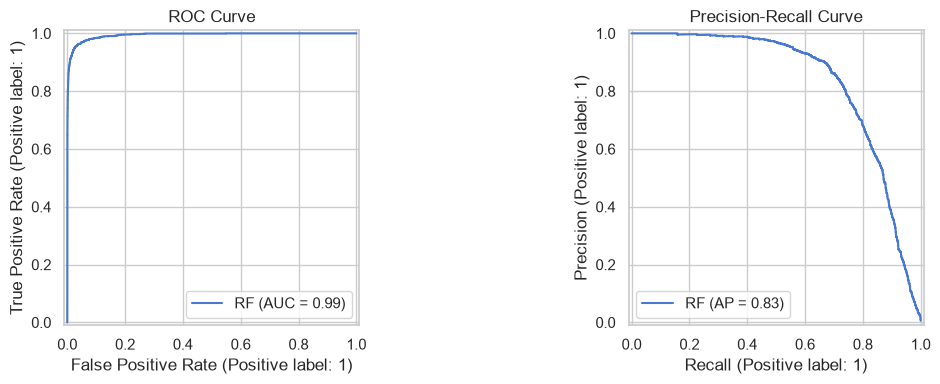

In [19]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf.fit(X_train, y_train)

prob_val_rf  = rf.predict_proba(X_val)[:, 1]
prob_test_rf = rf.predict_proba(X_test)[:, 1]

thr_rf = select_threshold(y_val, prob_val_rf)
metrics_rf = evaluate(y_test, prob_test_rf, threshold=thr_rf, name="Random Forest")
plot_curves(y_test, prob_test_rf, name="RF")

### 6.3 XGBoost (strong classical baseline)

XGBoost with `scale_pos_weight` is still the work-horse of many production fraud systems.

scale_pos_weight = 171.7

=== XGBoost ===
  roc_auc     : 0.9985
  pr_auc      : 0.9142
  precision   : 0.8560
  recall      : 0.8274
  f1          : 0.8415
  threshold   : 0.9498
              precision    recall  f1-score   support

       legit      0.999     0.999     0.999    257834
       fraud      0.856     0.827     0.841      1501

    accuracy                          0.998    259335
   macro avg      0.927     0.913     0.920    259335
weighted avg      0.998     0.998     0.998    259335



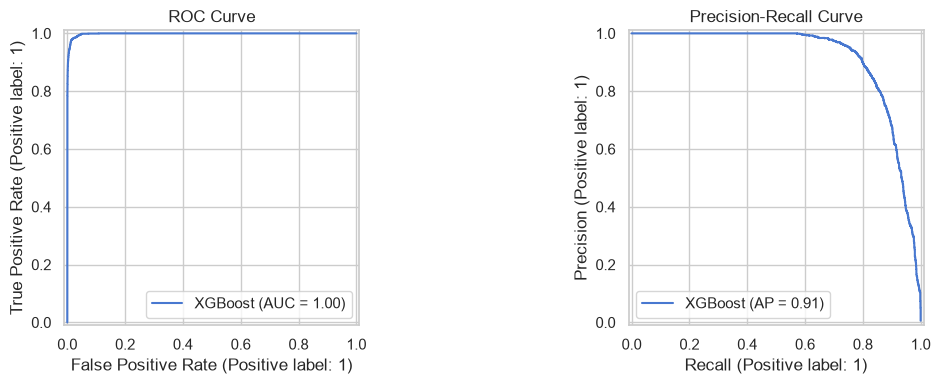

In [20]:
scale_pos = (y_train == 0).sum() / max((y_train == 1).sum(), 1)
print(f"scale_pos_weight = {scale_pos:.1f}")

xgb_clf = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos,
    eval_metric="aucpr",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    early_stopping_rounds=30
)
xgb_clf.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

prob_val_xgb  = xgb_clf.predict_proba(X_val)[:, 1]
prob_test_xgb = xgb_clf.predict_proba(X_test)[:, 1]

thr_xgb = select_threshold(y_val, prob_val_xgb)
metrics_xgb = evaluate(y_test, prob_test_xgb, threshold=thr_xgb, name="XGBoost")
plot_curves(y_test, prob_test_xgb, name="XGBoost")

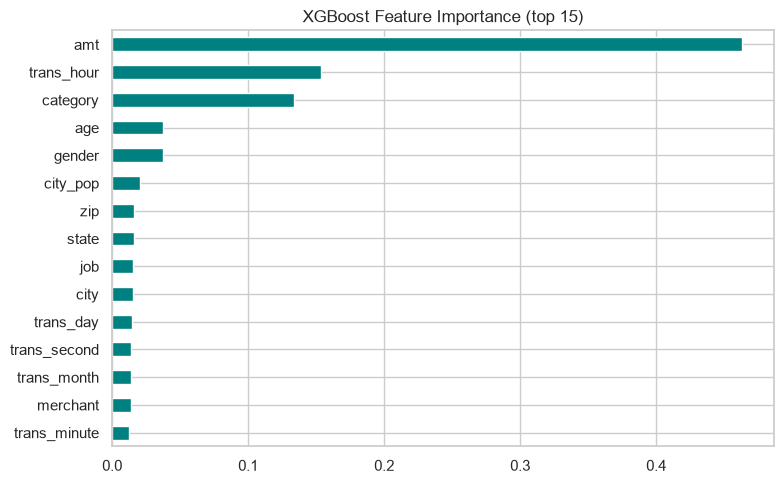

In [22]:
# Feature importance (top 15)
imp = pd.Series(
    xgb_clf.feature_importances_,
    index=NUMERICAL + CATEGORICAL
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
imp.head(15).plot(kind="barh", ax=ax, color="teal")
ax.invert_yaxis()
ax.set_title("XGBoost Feature Importance (top 15)")
plt.tight_layout()
plt.show()

## 7. Deep Learning – Embedding MLP

**Idea**: high-cardinality categoricals (merchant, city, job …) are mapped to low-dimensional dense vectors that the network can learn.  Numerical features are concatenated after the embeddings.

Architecture sketch:
```
categorical_i  → Embedding(card_i, 16)  ─┐
…                                        ├─ concat → Dense(256) → … → logit
numerical      → (already scaled)       ─┘
```

In [23]:
class EmbeddingMLP(nn.Module):
    def __init__(self, cardinalities, n_numerical, emb_dim=16, hidden=(256, 128, 64), dropout=0.25):
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(card, emb_dim) for card in cardinalities
        ])
        in_dim = len(cardinalities) * emb_dim + n_numerical
        layers = []
        for h in hidden:
            layers += [nn.Linear(in_dim, h), nn.PReLU(), nn.BatchNorm1d(h), nn.Dropout(dropout)]
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, cat, num):
        embs = [emb(cat[:, i]) for i, emb in enumerate(self.embeddings)]
        x = torch.cat(embs + [num], dim=1)
        return self.net(x).squeeze(1)


# Build cardinality list from the fitted label encoders
cardinalities = [len(prep.label_encoders[c].classes_) for c in CATEGORICAL]
print("Cardinalities:", list(zip(CATEGORICAL, cardinalities)))

mlp = EmbeddingMLP(cardinalities, n_numerical=len(NUMERICAL)).to(DEVICE)
print(mlp)

Cardinalities: [('gender', 3), ('job', 495), ('category', 15), ('city', 895), ('state', 52), ('zip', 971), ('merchant', 694), ('trans_hour', 25), ('trans_minute', 61), ('trans_second', 61), ('trans_year', 3), ('trans_month', 13), ('trans_day', 32)]
EmbeddingMLP(
  (embeddings): ModuleList(
    (0): Embedding(3, 16)
    (1): Embedding(495, 16)
    (2): Embedding(15, 16)
    (3): Embedding(895, 16)
    (4): Embedding(52, 16)
    (5): Embedding(971, 16)
    (6): Embedding(694, 16)
    (7): Embedding(25, 16)
    (8-9): 2 x Embedding(61, 16)
    (10): Embedding(3, 16)
    (11): Embedding(13, 16)
    (12): Embedding(32, 16)
  )
  (net): Sequential(
    (0): Linear(in_features=212, out_features=256, bias=True)
    (1): PReLU(num_parameters=1)
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): PReLU(num_parameters=1)
    (6): BatchNorm

In [24]:
def make_loader(frame, batch_size=256, shuffle=False):
    cats, nums = prep.transform(frame)
    y = frame[TARGET].values.astype(np.float32)
    ds = TensorDataset(
        torch.from_numpy(cats).long(),
        torch.from_numpy(nums).float(),
        torch.from_numpy(y)
    )
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(train_df, shuffle=True)
val_loader   = make_loader(val_df)
test_loader  = make_loader(test_df)

# Pos weight for BCEWithLogitsLoss
pos_weight = torch.tensor([scale_pos], device=DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(mlp.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", patience=3, factor=0.5)

def run_epoch(model, loader, train=True):
    model.train(train)
    total_loss, probs, labels = 0.0, [], []
    for cat, num, y in loader:
        cat, num, y = cat.to(DEVICE), num.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train):
            logits = model(cat, num)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * len(y)
        probs.append(torch.sigmoid(logits).detach().cpu().numpy())
        labels.append(y.cpu().numpy())
    probs = np.concatenate(probs)
    labels = np.concatenate(labels)
    pr_auc = average_precision_score(labels, probs)
    return total_loss / len(labels), pr_auc, probs

# Training loop with early stopping on val PR-AUC
best_pr, best_state, patience, wait = 0.0, None, 8, 0
history = []

for epoch in range(1, 41):
    tr_loss, tr_pr, _ = run_epoch(mlp, train_loader, train=True)
    va_loss, va_pr, _ = run_epoch(mlp, val_loader, train=False)
    scheduler.step(va_pr)
    history.append({"epoch": epoch, "train_pr": tr_pr, "val_pr": va_pr})
    print(f"Epoch {epoch:02d}  train_pr={tr_pr:.4f}  val_pr={va_pr:.4f}")

    if va_pr > best_pr:
        best_pr = va_pr
        best_state = {k: v.cpu().clone() for k, v in mlp.state_dict().items()}
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping.")
            break

mlp.load_state_dict(best_state)
print(f"Best validation PR-AUC: {best_pr:.4f}")

Epoch 01  train_pr=0.2070  val_pr=0.2976
Epoch 02  train_pr=0.3786  val_pr=0.6010
Epoch 03  train_pr=0.5258  val_pr=0.6270
Epoch 04  train_pr=0.6091  val_pr=0.6226
Epoch 05  train_pr=0.6430  val_pr=0.7080
Epoch 06  train_pr=0.7017  val_pr=0.7209
Epoch 07  train_pr=0.7268  val_pr=0.6834
Epoch 08  train_pr=0.7519  val_pr=0.7336
Epoch 09  train_pr=0.7727  val_pr=0.7058
Epoch 10  train_pr=0.7909  val_pr=0.7626
Epoch 11  train_pr=0.8141  val_pr=0.7360
Epoch 12  train_pr=0.8199  val_pr=0.7513
Epoch 13  train_pr=0.8359  val_pr=0.7593
Epoch 14  train_pr=0.8502  val_pr=0.7497
Epoch 15  train_pr=0.8898  val_pr=0.7807
Epoch 16  train_pr=0.9074  val_pr=0.7763
Epoch 17  train_pr=0.9217  val_pr=0.7784
Epoch 18  train_pr=0.9236  val_pr=0.7858
Epoch 19  train_pr=0.9278  val_pr=0.7936
Epoch 20  train_pr=0.9362  val_pr=0.7908
Epoch 21  train_pr=0.9383  val_pr=0.7986
Epoch 22  train_pr=0.9408  val_pr=0.7966
Epoch 23  train_pr=0.9485  val_pr=0.7923
Epoch 24  train_pr=0.9500  val_pr=0.8085
Epoch 25  train_


=== Embedding MLP ===
  roc_auc     : 0.9758
  pr_auc      : 0.8271
  precision   : 0.8466
  recall      : 0.7428
  f1          : 0.7913
  threshold   : 0.9842
              precision    recall  f1-score   support

       legit      0.999     0.999     0.999    257834
       fraud      0.847     0.743     0.791      1501

    accuracy                          0.998    259335
   macro avg      0.923     0.871     0.895    259335
weighted avg      0.998     0.998     0.998    259335



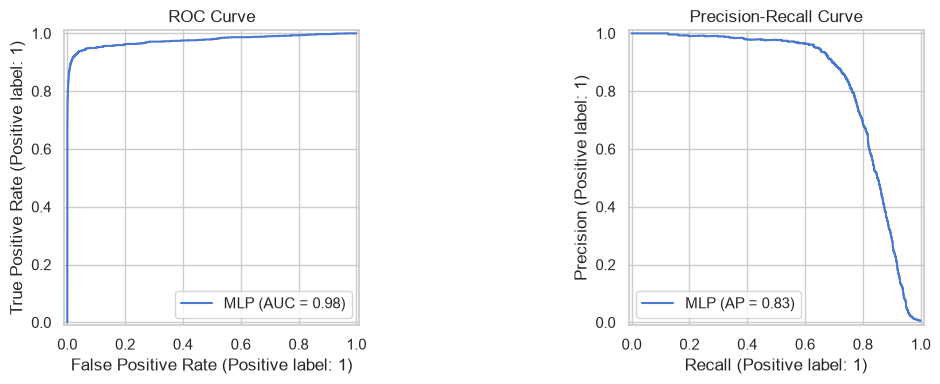

In [25]:
# Final MLP evaluation
_, _, prob_val_mlp  = run_epoch(mlp, val_loader, train=False)
_, _, prob_test_mlp = run_epoch(mlp, test_loader, train=False)

thr_mlp = select_threshold(y_val, prob_val_mlp)
metrics_mlp = evaluate(y_test, prob_test_mlp, threshold=thr_mlp, name="Embedding MLP")
plot_curves(y_test, prob_test_mlp, name="MLP")

## 8. Graph Neural Network – Bipartite GraphSAGE

### Why a graph?
Fraud often propagates through **shared merchants** or **compromised cards**.  
We build a bipartite graph:

```
Card nodes  ←──transactions──→  Merchant nodes
```

Each transaction is an **edge** that carries numerical features (`amt`, `distance`, …).  
GraphSAGE learns node embeddings by aggregating neighbour information; we then classify the *edge* (i.e. the transaction).

> Implementation note: we use a pure-PyTorch sparse-matrix GraphSAGE so the notebook has zero extra graph-library dependencies.

In [26]:
class SageLayer(nn.Module):
    """Mean-aggregator GraphSAGE layer."""
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.self_lin = nn.Linear(in_dim, out_dim)
        self.neigh_lin = nn.Linear(in_dim, out_dim)

    def forward(self, x, adj):
        # adj is a sparse (n_nodes × n_nodes) normalised adjacency
        neigh = torch.sparse.mm(adj, x)
        return torch.relu(self.self_lin(x) + self.neigh_lin(neigh))


class BipartiteFraudGNN(nn.Module):
    def __init__(self, n_nodes, edge_dim, hidden=48):
        super().__init__()
        self.node_emb = nn.Embedding(n_nodes, hidden)
        self.sage1 = SageLayer(hidden, hidden)
        self.sage2 = SageLayer(hidden, hidden)
        self.drop = nn.Dropout(0.15)
        # edge classifier: [h_src || h_dst || h_src*h_dst || edge_feat]
        self.edge_mlp = nn.Sequential(
            nn.Linear(hidden * 3 + edge_dim, 128),
            nn.PReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 32),
            nn.PReLU(),
            nn.Linear(32, 1)
        )

    def encode(self, adj):
        x = self.node_emb.weight
        x = self.drop(self.sage1(x, adj))
        return self.sage2(x, adj)

    def score_edges(self, h, src, dst, edge_feat):
        h_s, h_d = h[src], h[dst]
        # simple interaction term
        inter = h_s * h_d
        x = torch.cat([h_s, h_d, inter, edge_feat], dim=1)
        return self.edge_mlp(x).squeeze(1)

In [27]:
# ---------- Build the bipartite graph from TRAINING edges only (no leakage) ----------
def build_graph(train_frame, full_frame):
    """Return node maps, sparse adjacency (train only), and edge tensors for any split."""
    cards = sorted(train_frame[CARD_COL].unique())
    merchants = sorted(train_frame[MERCHANT_COL].unique())
    # also include any nodes that appear only in val/test so indexing stays valid
    all_cards = sorted(set(cards) | set(full_frame[CARD_COL].unique()))
    all_merchants = sorted(set(merchants) | set(full_frame[MERCHANT_COL].unique()))

    card2idx = {c: i for i, c in enumerate(all_cards)}
    merch2idx = {m: i + len(all_cards) for i, m in enumerate(all_merchants)}
    n_nodes = len(all_cards) + len(all_merchants)

    # adjacency from *training* transactions only
    src = train_frame[CARD_COL].map(card2idx).values
    dst = train_frame[MERCHANT_COL].map(merch2idx).values
    # undirected for message passing
    rows = np.concatenate([src, dst])
    cols = np.concatenate([dst, src])
    data = np.ones(len(rows), dtype=np.float32)
    indices = torch.from_numpy(np.vstack([rows, cols])).long()
    values = torch.from_numpy(data)
    adj = torch.sparse_coo_tensor(indices, values, (n_nodes, n_nodes)).coalesce()
    # degree normalisation (simple mean aggregator)
    deg = torch.sparse.sum(adj, dim=1).to_dense().clamp(min=1)
    norm_values = values / deg[rows]
    adj = torch.sparse_coo_tensor(indices, norm_values, (n_nodes, n_nodes)).coalesce()

    return card2idx, merch2idx, adj, n_nodes


card2idx, merch2idx, adj, n_nodes = build_graph(train_df, df)
adj = adj.to(DEVICE)
print(f"Graph: {n_nodes} nodes  ({len(card2idx)} cards + {len(merch2idx)} merchants)")
print(f"Training edges: {len(train_df)}")

Graph: 1676 nodes  (983 cards + 693 merchants)
Training edges: 778005


In [28]:
def edge_tensors(frame, card2idx, merch2idx):
    """Return src, dst index tensors and scaled edge features."""
    src = torch.tensor(frame[CARD_COL].map(card2idx).values, dtype=torch.long)
    dst = torch.tensor(frame[MERCHANT_COL].map(merch2idx).values, dtype=torch.long)
    # edge features = the 4 numerical columns (already scaled by the tabular preprocessor)
    _, nums = prep.transform(frame)
    edge_feat = torch.from_numpy(nums).float()
    y = torch.tensor(frame[TARGET].values, dtype=torch.float32)
    return src, dst, edge_feat, y


src_tr, dst_tr, feat_tr, y_tr = edge_tensors(train_df, card2idx, merch2idx)
src_va, dst_va, feat_va, y_va = edge_tensors(val_df,   card2idx, merch2idx)
src_te, dst_te, feat_te, y_te = edge_tensors(test_df,  card2idx, merch2idx)

# move to device
src_tr, dst_tr, feat_tr, y_tr = [t.to(DEVICE) for t in (src_tr, dst_tr, feat_tr, y_tr)]
src_va, dst_va, feat_va, y_va = [t.to(DEVICE) for t in (src_va, dst_va, feat_va, y_va)]
src_te, dst_te, feat_te, y_te = [t.to(DEVICE) for t in (src_te, dst_te, feat_te, y_te)]

In [29]:
gnn = BipartiteFraudGNN(n_nodes, edge_dim=len(NUMERICAL), hidden=48).to(DEVICE)
opt_gnn = torch.optim.AdamW(gnn.parameters(), lr=3e-3, weight_decay=1e-4)
crit_gnn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

best_pr_gnn, best_gnn_state, wait = 0.0, None, 0

for epoch in range(1, 61):
    gnn.train()
    opt_gnn.zero_grad()
    h = gnn.encode(adj)
    logits = gnn.score_edges(h, src_tr, dst_tr, feat_tr)
    loss = crit_gnn(logits, y_tr)
    loss.backward()
    opt_gnn.step()

    # validation
    gnn.eval()
    with torch.no_grad():
        h = gnn.encode(adj)
        prob_va = torch.sigmoid(gnn.score_edges(h, src_va, dst_va, feat_va)).cpu().numpy()
    pr = average_precision_score(y_val, prob_va)
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}  loss={loss.item():.4f}  val_pr={pr:.4f}")

    if pr > best_pr_gnn:
        best_pr_gnn = pr
        best_gnn_state = {k: v.cpu().clone() for k, v in gnn.state_dict().items()}
        wait = 0
    else:
        wait += 1
        if wait >= 12:
            print("Early stopping GNN.")
            break

gnn.load_state_dict(best_gnn_state)
print(f"Best GNN validation PR-AUC: {best_pr_gnn:.4f}")

Epoch 01  loss=1.3797  val_pr=0.1782
Epoch 05  loss=1.1647  val_pr=0.1832
Epoch 10  loss=0.9176  val_pr=0.1871
Epoch 15  loss=0.8561  val_pr=0.1902
Epoch 20  loss=0.8000  val_pr=0.1915
Epoch 25  loss=0.7736  val_pr=0.1947
Epoch 30  loss=0.7410  val_pr=0.1995
Epoch 35  loss=0.7085  val_pr=0.2052
Epoch 40  loss=0.6753  val_pr=0.2097
Epoch 45  loss=0.6466  val_pr=0.2123
Epoch 50  loss=0.6215  val_pr=0.2159
Epoch 55  loss=0.6087  val_pr=0.2175
Epoch 60  loss=0.5869  val_pr=0.2192
Best GNN validation PR-AUC: 0.2192



=== GraphSAGE GNN ===
  roc_auc     : 0.9239
  pr_auc      : 0.2245
  precision   : 0.3629
  recall      : 0.4744
  f1          : 0.4112
  threshold   : 0.9694
              precision    recall  f1-score   support

       legit      0.997     0.995     0.996    257834
       fraud      0.363     0.474     0.411      1501

    accuracy                          0.992    259335
   macro avg      0.680     0.735     0.704    259335
weighted avg      0.993     0.992     0.993    259335



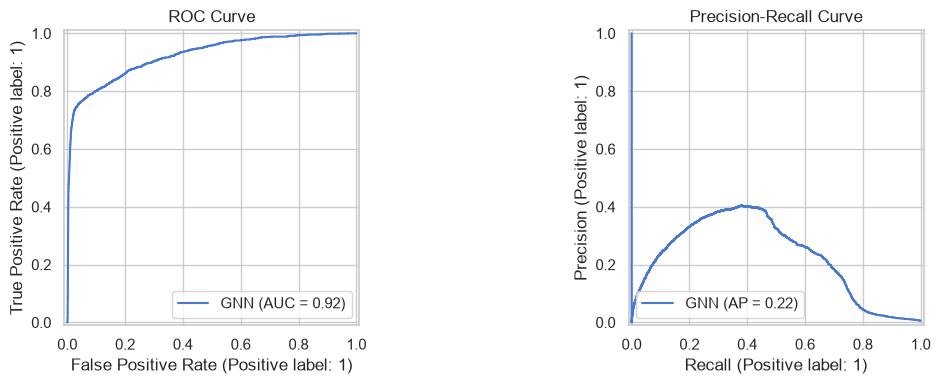

In [30]:
# Final GNN evaluation
gnn.eval()
with torch.no_grad():
    h = gnn.encode(adj)
    prob_val_gnn  = torch.sigmoid(gnn.score_edges(h, src_va, dst_va, feat_va)).cpu().numpy()
    prob_test_gnn = torch.sigmoid(gnn.score_edges(h, src_te, dst_te, feat_te)).cpu().numpy()

thr_gnn = select_threshold(y_val, prob_val_gnn)
metrics_gnn = evaluate(y_test, prob_test_gnn, threshold=thr_gnn, name="GraphSAGE GNN")
plot_curves(y_test, prob_test_gnn, name="GNN")

## 9. Hybrid Idea (GNN embeddings + XGBoost)

A practical pattern used in industry: extract the learned node embeddings from the GNN and concatenate them to the original tabular features, then train a gradient-boosted tree.  This often yields a small but consistent lift.


=== Hybrid (GNN+XGB) ===
  roc_auc     : 0.9968
  pr_auc      : 0.8894
  precision   : 0.8824
  recall      : 0.7801
  f1          : 0.8281
  threshold   : 0.9562
              precision    recall  f1-score   support

       legit      0.999     0.999     0.999    257834
       fraud      0.882     0.780     0.828      1501

    accuracy                          0.998    259335
   macro avg      0.941     0.890     0.914    259335
weighted avg      0.998     0.998     0.998    259335



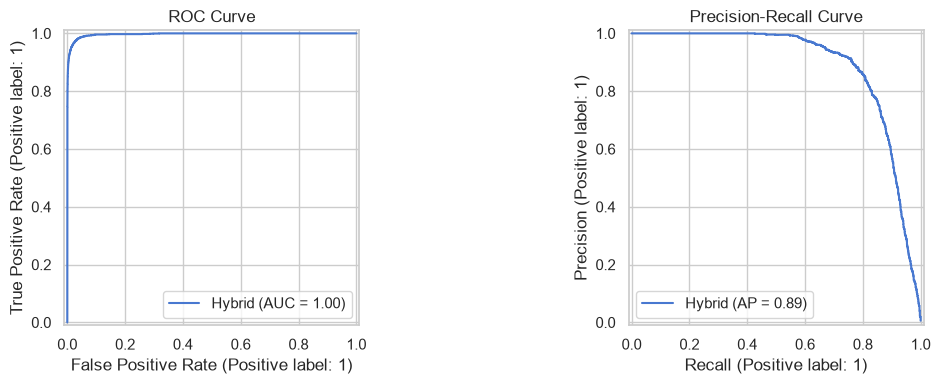

In [31]:
gnn.eval()
with torch.no_grad():
    node_h = gnn.encode(adj).cpu().numpy()   # (n_nodes, hidden)

def add_gnn_features(frame, X_tab):
    """Concatenate mean of card & merchant embeddings to the tabular matrix."""
    c_idx = frame[CARD_COL].map(card2idx).values
    m_idx = frame[MERCHANT_COL].map(merch2idx).values
    emb = (node_h[c_idx] + node_h[m_idx]) / 2.0
    return np.hstack([X_tab, emb.astype(np.float32)])

X_train_h = add_gnn_features(train_df, X_train)
X_val_h   = add_gnn_features(val_df,   X_val)
X_test_h  = add_gnn_features(test_df,  X_test)

xgb_hybrid = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos,
    eval_metric="aucpr",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    early_stopping_rounds=30
)
xgb_hybrid.fit(
    X_train_h, y_train,
    eval_set=[(X_val_h, y_val)],
    verbose=False
)

prob_val_hyb  = xgb_hybrid.predict_proba(X_val_h)[:, 1]
prob_test_hyb = xgb_hybrid.predict_proba(X_test_h)[:, 1]

thr_hyb = select_threshold(y_val, prob_val_hyb)
metrics_hyb = evaluate(y_test, prob_test_hyb, threshold=thr_hyb, name="Hybrid (GNN+XGB)")
plot_curves(y_test, prob_test_hyb, name="Hybrid")

## 10. Model Comparison Summary

,roc_auc,pr_auc,precision,recall,f1,threshold
Logistic Regression,0.8622,0.2059,0.3803,0.4750,0.4224,0.9639
Random Forest,0.9939,0.8326,0.8396,0.7182,0.7741,0.7837
XGBoost,0.9985,0.9142,0.8560,0.8274,0.8415,0.9498
Embedding MLP,0.9758,0.8271,0.8466,0.7428,0.7913,0.9842
GraphSAGE GNN,0.9239,0.2245,0.3629,0.4744,0.4112,0.9694
Hybrid GNN+XGB,0.9968,0.8894,0.8824,0.7801,0.8281,0.9562


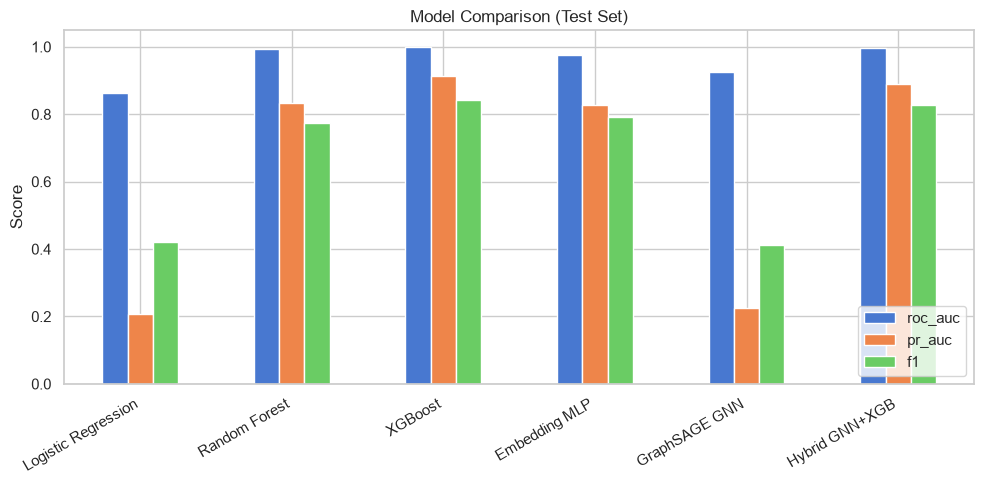

In [32]:
results = pd.DataFrame({
    "Logistic Regression": metrics_lr,
    "Random Forest":       metrics_rf,
    "XGBoost":             metrics_xgb,
    "Embedding MLP":       metrics_mlp,
    "GraphSAGE GNN":       metrics_gnn,
    "Hybrid GNN+XGB":      metrics_hyb,
}).T

display(results[["roc_auc", "pr_auc", "precision", "recall", "f1", "threshold"]].round(4))

# Visual comparison
fig, ax = plt.subplots(figsize=(10, 5))
results[["roc_auc", "pr_auc", "f1"]].plot(kind="bar", ax=ax)
ax.set_title("Model Comparison (Test Set)")
ax.set_ylabel("Score")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

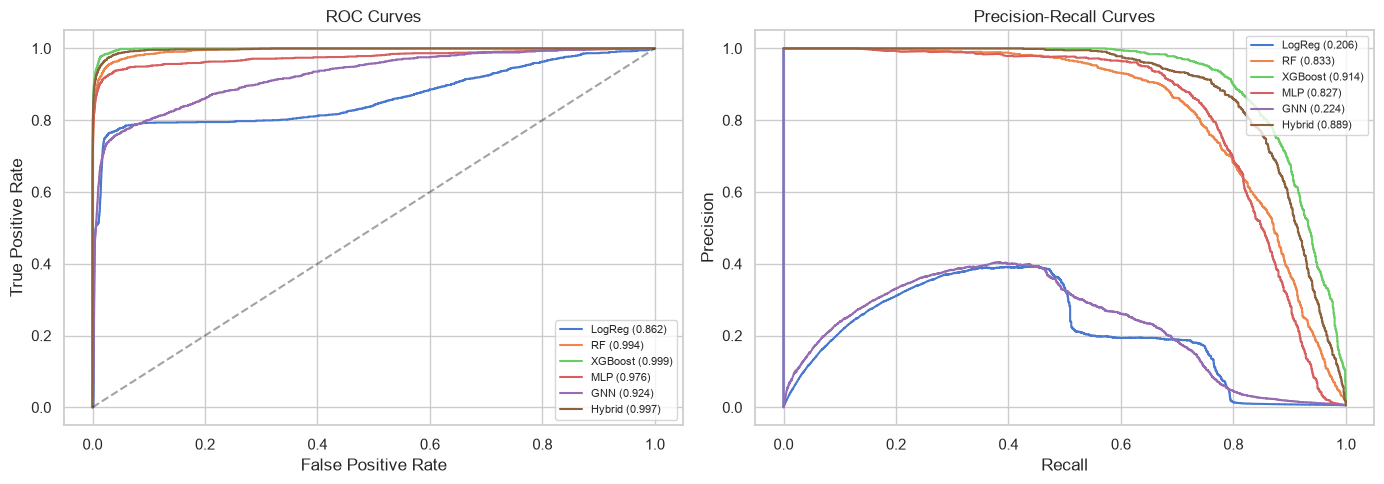

In [33]:
# Side-by-side ROC & PR curves for all models
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, prob in [
    ("LogReg",   prob_test_lr),
    ("RF",       prob_test_rf),
    ("XGBoost",  prob_test_xgb),
    ("MLP",      prob_test_mlp),
    ("GNN",      prob_test_gnn),
    ("Hybrid",   prob_test_hyb),
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, prob):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(rec, prec, label=f"{name} ({average_precision_score(y_test, prob):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curves")
axes[0].legend(loc="lower right", fontsize=8)

axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curves")
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

## 11. Key Take-aways

1. **Class imbalance** dominates the problem – always report **PR-AUC** and a validation-chosen threshold, not accuracy.
2. **XGBoost** remains an extremely strong and practical baseline for tabular fraud data.
3. **Embedding MLP** learns useful representations of high-cardinality categoricals and often matches or exceeds tree models when enough data is present.
4. **GraphSAGE** on the card–merchant bipartite graph can surface relational fraud patterns (shared compromised merchants, fraud rings) that pure tabular models miss.
5. **Hybrid** (GNN embeddings + XGBoost) is a simple way to combine the best of both worlds and is frequently used in production pipelines.
6. **Leakage control** is non-negotiable: fit encoders/scalers and build the graph adjacency **only on training data**.

